In [1]:
from pathlib import Path
import os
import sys

# 无论从仓库根目录还是 notebook 目录启动，都统一回到仓库根目录。
repo_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / 'factors').is_dir() and (path / 'data').is_dir()
)
os.chdir(repo_root)
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

%load_ext autoreload
%autoreload 2

# 全曲线斜率单因子实验 `CurveSlope`

本实验固定使用 2000-01-01 至 2024-12-31 的主面板与期限结构数据，以 `market_rank_ls` 诊断组合比较不同的曲线加权方式与合约筛选区间。参数只围绕经济机制展开：回归权重（`OpenInterest` / `Volume`）和剩余到期日区间（`min_dte` / `max_dte`）；价格口径固定为 `Close`，拟合所需最少合约数固定为 3。

`CurveSlope` 单次计算约 1 分钟，因此本实验只预计算 6 个因子变体，再把同一批因子值复用到 12 个持有期上。


In [2]:
from collections.abc import Mapping
from contextlib import redirect_stdout
from dataclasses import replace
from typing import Any
import datetime
import io
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from tqdm.auto import tqdm

from factors import presets
from factors.diagnostic_portfolio import DiagnosticPortfolioExperimentRunner
from factors.exploration import xray
from factors.library.basic import CurveSlope
from factors.scanning import (
    EvaluationResult, gen_candidate_grid, run_scan,
)


## 构造研究数据集


In [3]:
start_date = datetime.date(2000, 1, 1)
end_date = datetime.date(2024, 12, 31)

# 数据管理器会逐品种打印缓存加载信息；这里只保留实验摘要。
with redirect_stdout(io.StringIO()):
    dataset, facade = presets.build_dataset_with_facade(
        start_date=start_date,
        end_date=end_date,
        sources=presets.MAIN_PANEL_AND_TERM_STRUCTURE,
    )

assert dataset.auxiliary is not None
term_structure = dataset.auxiliary['term_structure']
print(f'主面板：{len(dataset.main_panel):,} 行，'
      f'{dataset.main_panel.index.get_level_values("product").nunique()} 个品种')
print(f'期限结构：{len(term_structure):,} 行，'
      f'{term_structure.index.get_level_values("product").nunique()} 个品种')
print(f'样本区间：{start_date} 至 {end_date}')


主面板缺品种提醒：以下品种数据引擎返回了空 DataFrame。在主面板中会缺失：['AD', 'BZ', 'OP', 'PD', 'PL', 'PT']


D:\量化策略\CTA策略\early-bird-alpha\data\facade.py:381: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat(dfs, axis=0)


期限结构数据缺品种提醒：以下品种数据引擎返回了空 DataFrame。在期限结构数据中会缺失：{'PT', 'AD', 'PL', 'PD', 'BZ', 'OP'}


主面板：218,288 行，88 个品种
期限结构：2,040,176 行，88 个品种
样本区间：2000-01-01 至 2024-12-31


## 参数空间与因子预计算

- `OpenInterest` 加权：更接近存量风险分布，受单日成交冲击较小。
- `Volume` 加权：更偏向当日最活跃合约，流动性更好但噪声更大。
- DTE `3-300`：默认口径，作为基准。
- DTE `3-180`：收缩长端，检验远月合约是否稀释斜率信号。
- DTE `14-300`：剔除临近交割合约，检验交割扰动。
- `min_volume=100`、`price_col='Close'`、`min_contract_fit=3` 固定，避免把计算预算摊到次要轴上。

每个变体只 `compute` 一次，共 6 次；后续 72 次诊断组合运行复用这些因子值。


In [4]:
# 6 个变体：2 种回归权重 × 3 个 DTE 区间。
# 每个变体只计算一次；CurveSlope 单次计算约 1 分钟，因此不再扩展其他轴。
VARIANT_SPECS: list[dict[str, Any]] = [
    {
        'variant': f'{weight_tag}_{min_dte}-{max_dte}',
        'weight_var': weight_var,
        'contract_filter_rule': {
            'min_dte': min_dte, 'max_dte': max_dte, 'min_volume': 100,
        },
        'price_col': 'Close',
        'min_contract_fit': 3,
    }
    for weight_var, weight_tag in (
        ('OpenInterest', 'OI'), ('Volume', 'VOL'),
    )
    for min_dte, max_dte in ((3, 180), (3, 300), (14, 300))
]

factor_values: dict[str, pd.Series] = {}
diagnostics: list[dict[str, Any]] = []

# CurveSlope 每个截面都会记录警告，日志会刷屏；预计算期间只保留错误级别。
factor_logger = logging.getLogger('factors.library.basic')
previous_level = factor_logger.level
factor_logger.setLevel(logging.ERROR)
try:
    for spec in tqdm(VARIANT_SPECS, desc='预计算 CurveSlope 变体'):
        variant = spec['variant']
        params = {
            key: value for key, value in spec.items() if key != 'variant'
        }
        factor = CurveSlope(**params)
        values = factor.compute(term_structure)
        factor_values[variant] = values
        # warnings 只保留前 100 条，总数要看 _warning_count。
        warning_count = getattr(
            factor, '_warning_count', len(factor.warnings))
        diagnostics.append({
            'variant': variant,
            'weight_var': params['weight_var'],
            'min_dte': params['contract_filter_rule']['min_dte'],
            'max_dte': params['contract_filter_rule']['max_dte'],
            'min_volume': params['contract_filter_rule']['min_volume'],
            'min_contract_fit': params['min_contract_fit'],
            'valid_count': int(values.notna().sum()),
            'coverage': float(values.notna().mean()),
            'warning_count': int(warning_count),
        })
finally:
    factor_logger.setLevel(previous_level)

diagnostics_table = pd.DataFrame(diagnostics).set_index('variant')
assert len(factor_values) == 6
display(diagnostics_table.style.format({'coverage': '{:.2%}'}))


,weight_var,min_dte,max_dte,min_volume,min_contract_fit,valid_count,coverage,warning_count
variant,,,,,,,,
OI_3-180,OpenInterest,3,180,100,3,110346,50.56%,107896
OI_3-300,OpenInterest,3,300,100,3,147374,67.53%,70868
OI_14-300,OpenInterest,14,300,100,3,144393,66.16%,73849
VOL_3-180,Volume,3,180,100,3,110346,50.56%,107896
VOL_3-300,Volume,3,300,100,3,147374,67.53%,70868
VOL_14-300,Volume,14,300,100,3,144393,66.16%,73849


## 代表信号分布

以 DTE `3-300` 为代表，比较 `OpenInterest` 与 `Volume` 两种加权方式下的因子分布。


Summary Statistics of curve_slope_OpenInterest_Close_dte3-300_vol100_n3
count    147374.000000
mean          0.009707
std           0.149029
min          -2.604285
1%           -0.371363
25%          -0.059198
50%          -0.000504
75%           0.068526
99%           0.442127
max           1.949525
Percentage of 0: 0.00%
Percentage of NaN: 32.47%; total length=218242
N unique values: 147374
Percentage of positive: 33.57%
Percentage of negative: 33.96%



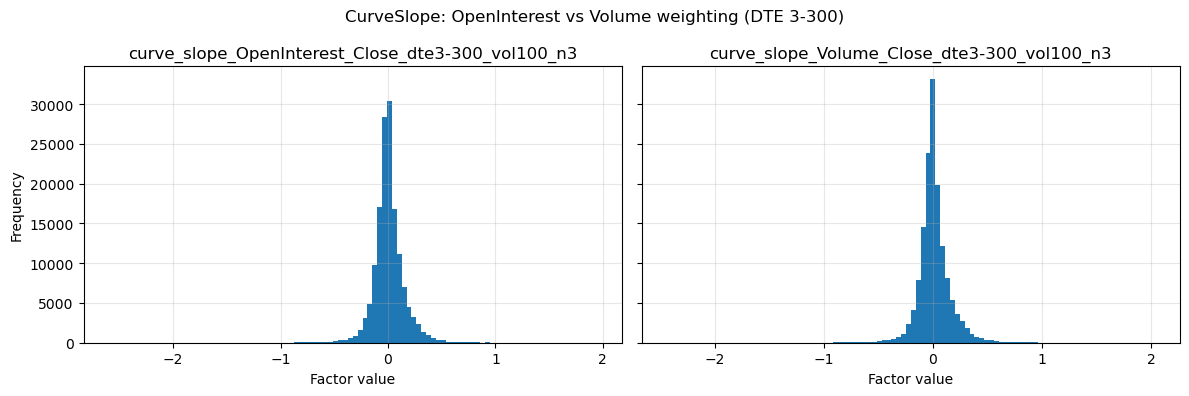

In [5]:
representative_variant = 'OI_3-300'
representative_values = factor_values[representative_variant]
_ = xray.quick_glance_at(representative_values, print_out=True)
_ = xray.plot_hist(
    representative_values,
    factor_values['VOL_3-300'],
    bins=100,
    suptitle='CurveSlope: OpenInterest vs Volume weighting (DTE 3-300)',
)


## 诊断组合参数扫描

对每组因子值扫描 `h = 5, 10, ..., 60`，使用截面市场中性的 `market_rank_ls` 配方，以代理成本后收益的 Sharpe 与 CAGR 评价。


In [6]:
experiment_params = {'h': range(5, 65, 5)}
candidate_grid = {
    'variant': [spec['variant'] for spec in VARIANT_SPECS],
    **experiment_params,
}
candidates = gen_candidate_grid(candidate_grid)
assert len(candidates) == 6 * 12


def evaluate_mrls(params: Mapping[str, Any]) -> EvaluationResult:
    """运行一组截面市场中性诊断组合。"""
    signal = replace(
        presets.base_signal, values=factor_values[params['variant']])
    rebalance = replace(
        presets.base_rebalance_config, interval=params['h'])
    spec = replace(presets.mrls_base_spec, rebalance=rebalance)
    runner = DiagnosticPortfolioExperimentRunner(
        signal=signal, dataset=dataset, spec=spec,
    )
    portfolio_result = runner.run()
    metrics = {
        'sharpe': float(portfolio_result.performance.loc['proxy_net', 'sharpe']),
        'cagr': float(portfolio_result.performance.loc['proxy_net', 'cagr']),
    }
    return EvaluationResult(
        metrics=metrics, warnings=tuple(portfolio_result.warnings),
    )


scan_result = run_scan(
    evaluate_func=evaluate_mrls,
    candidates=candidates,
    error_policy='raise',
    progress_bar=True,
    desc='扫描 CurveSlope 参数',
)


## 完整结果与最优候选


In [7]:
variant_meta = diagnostics_table.reset_index()[[
    'variant', 'weight_var', 'min_dte', 'max_dte',
]].copy()
variant_meta['dte_band'] = (
    variant_meta['min_dte'].astype(str)
    + '-'
    + variant_meta['max_dte'].astype(str)
)

scan_table = pd.concat(
    [scan_result.candidate_params, scan_result.eval_metrics], axis=1,
).join(variant_meta.set_index('variant'), on='variant')
scan_table.index.name = 'candidate_id'
assert len(scan_table) == 72

ranking = scan_table.sort_values(['sharpe', 'cagr'], ascending=False)
best_candidate = ranking.iloc[0]
print('最佳候选：')
display(best_candidate.to_frame('value'))
print('Sharpe 排名前 10：')
display(ranking.head(10))
print(f'完整候选结果（{len(scan_table)} 行）：')
with pd.option_context('display.max_rows', None):
    display(scan_table)


最佳候选：


,value
variant,OI_3-300
h,55
sharpe,1.171211
cagr,0.072849
weight_var,OpenInterest
min_dte,3
max_dte,300
dte_band,3-300


Sharpe 排名前 10：


,variant,h,sharpe,cagr,weight_var,min_dte,max_dte,dte_band
candidate_id,,,,,,,,
cand_0022,OI_3-300,55,1.171211,0.072849,OpenInterest,3,300,3-300
cand_0034,OI_14-300,55,1.093125,0.068091,OpenInterest,14,300,14-300
cand_0024,OI_14-300,5,1.050151,0.067754,OpenInterest,14,300,14-300
cand_0012,OI_3-300,5,1.036922,0.066370,OpenInterest,3,300,3-300
cand_0058,VOL_3-300,55,1.008756,0.062266,Volume,3,300,3-300
cand_0048,VOL_3-300,5,0.996146,0.063409,Volume,3,300,3-300
cand_0017,OI_3-300,30,0.972716,0.060470,OpenInterest,3,300,3-300
cand_0070,VOL_14-300,55,0.968949,0.060485,Volume,14,300,14-300
cand_0029,OI_14-300,30,0.953761,0.059483,OpenInterest,14,300,14-300


完整候选结果（72 行）：


,variant,h,sharpe,cagr,weight_var,min_dte,max_dte,dte_band
candidate_id,,,,,,,,
cand_0000,OI_3-180,5,0.798178,0.056334,OpenInterest,3,180,3-180
cand_0001,OI_3-180,10,0.636105,0.043708,OpenInterest,3,180,3-180
cand_0002,OI_3-180,15,0.636335,0.042977,OpenInterest,3,180,3-180
cand_0003,OI_3-180,20,0.679048,0.046488,OpenInterest,3,180,3-180
cand_0004,OI_3-180,25,0.720499,0.049548,OpenInterest,3,180,3-180
cand_0005,OI_3-180,30,0.773337,0.050855,OpenInterest,3,180,3-180
cand_0006,OI_3-180,35,0.796123,0.054473,OpenInterest,3,180,3-180
cand_0007,OI_3-180,40,0.771887,0.052673,OpenInterest,3,180,3-180
cand_0008,OI_3-180,45,0.707177,0.045822,OpenInterest,3,180,3-180


## 样本内结果摘要

- 最优候选为 `OI_3-300`、`h=55`：代理成本后 Sharpe `1.17`，CAGR `7.28%`。
- 同一 DTE 区间、同一持有期下，`OpenInterest` 加权在多数组合中优于 `Volume` 加权，提示存量持仓可能比单日成交更适合作为曲线回归的权重。
- DTE `3-300` 与 `14-300` 的结果接近，`3-180` 明显偏弱；但 `3-180` 的覆盖率只有 `50.56%`，其低 Sharpe 可能部分来自截面收缩，而不是纯粹的期限区间效应。
- 所有变体在 `h=55` 同时出现峰值，且 `h=5` 也普遍较好；这种跨变体一致的形态更像调仓日历或样本末端效应，不建议只依据 `h=55` 选参。


## Sharpe 热力图

左右两图分别为 `OpenInterest` 与 `Volume` 加权；横轴是三种 DTE 区间，纵轴是持有期 `h`。所有子图共享色标，格子内为代理成本后的 Sharpe。为避免中文字体缺失导致的 glyph warning，图中文字统一使用英文。


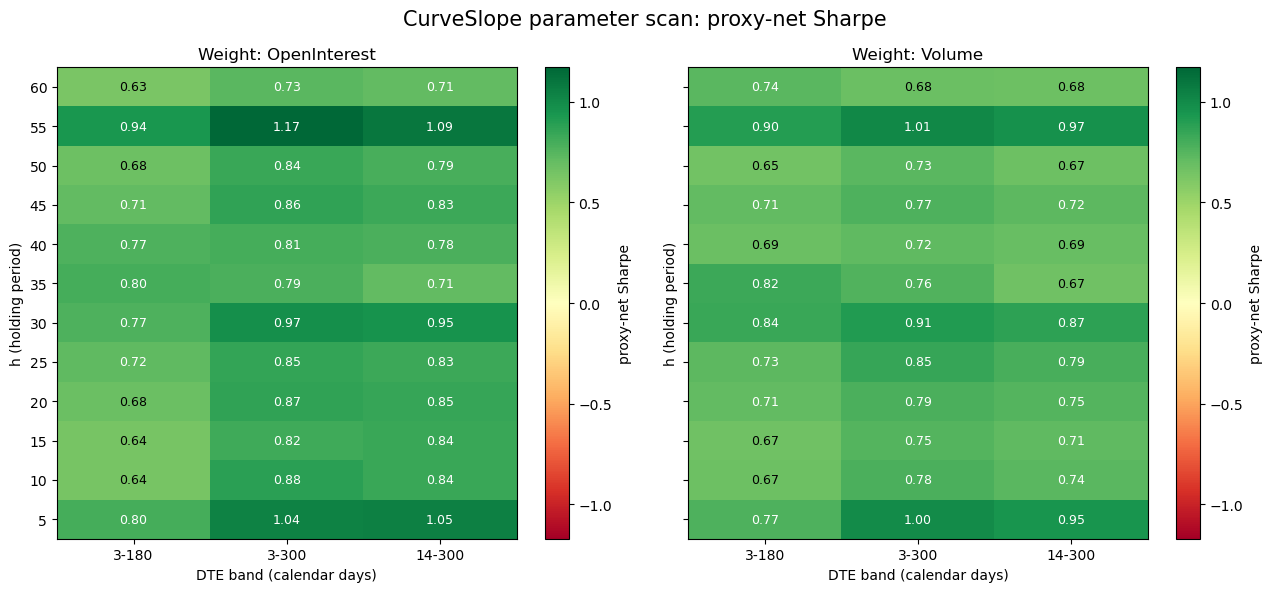

In [8]:
plot_data = scan_table.reset_index(drop=False).copy()
dte_order = ['3-180', '3-300', '14-300']
weight_order = ['OpenInterest', 'Volume']
h_order = list(range(5, 65, 5))

vabs = float(np.nanmax(np.abs(plot_data['sharpe'].to_numpy())))
vabs = max(vabs, 1e-9)
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
for ax, weight_var in zip(axes, weight_order):
    subset = plot_data[plot_data['weight_var'] == weight_var]
    heat = (
        subset.pivot(index='h', columns='dte_band', values='sharpe')
        .reindex(index=h_order, columns=dte_order)
    )
    image = ax.imshow(
        heat.to_numpy(), aspect='auto', origin='lower', cmap='RdYlGn',
        vmin=-vabs, vmax=vabs,
    )
    ax.set_xticks(range(len(dte_order)), dte_order)
    ax.set_yticks(range(len(h_order)), h_order)
    ax.set_xlabel('DTE band (calendar days)')
    ax.set_ylabel('h (holding period)')
    ax.set_title(f'Weight: {weight_var}')
    for i in range(heat.shape[0]):
        for j in range(heat.shape[1]):
            value = heat.iat[i, j]
            if pd.isna(value):
                continue
            color = 'black' if abs(value) < 0.6 * vabs else 'white'
            ax.text(
                j, i, f'{value:.2f}', ha='center', va='center',
                fontsize=9, color=color,
            )
    fig.colorbar(image, ax=ax, label='proxy-net Sharpe')

fig.suptitle('CurveSlope parameter scan: proxy-net Sharpe', fontsize=15)
fig.tight_layout()
plt.show()


## Sharpe 与持有期

同一变体在不同持有期下的 Sharpe 走势，用于判断结果对调仓频率的敏感度。


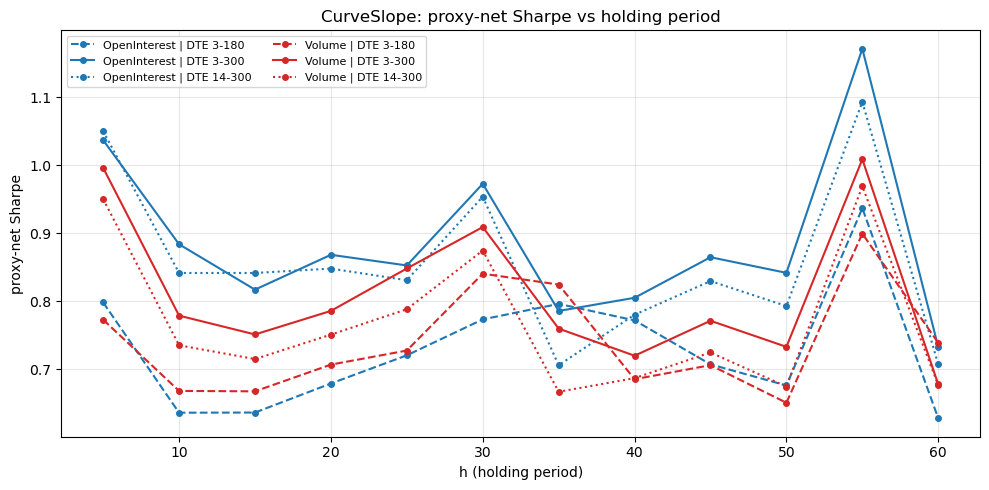

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
linestyles = {'3-180': '--', '3-300': '-', '14-300': ':'}
colors = {'OpenInterest': '#1f77b4', 'Volume': '#d62728'}
for spec in VARIANT_SPECS:
    variant = spec['variant']
    subset = scan_table[scan_table['variant'] == variant].sort_values('h')
    dte_band = (
        f"{spec['contract_filter_rule']['min_dte']}-"
        f"{spec['contract_filter_rule']['max_dte']}"
    )
    ax.plot(
        subset['h'], subset['sharpe'],
        label=f"{spec['weight_var']} | DTE {dte_band}",
        color=colors[spec['weight_var']],
        linestyle=linestyles[dte_band],
        marker='o', markersize=4,
    )
ax.set_xlabel('h (holding period)')
ax.set_ylabel('proxy-net Sharpe')
ax.set_title('CurveSlope: proxy-net Sharpe vs holding period')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()


## 解释边界

- 以上结果是同一样本内的机制比较，最优候选使用了完整样本进行选择，不能直接视为样本外结论。
- 6 个变体只覆盖了 `weight_var` 与 DTE 区间；`price_col='Settle'`、`min_contract_fit`、`min_volume` 未做敏感性测试。
- `3-180` 的覆盖率只有 `50.56%`，而 `3-300` / `14-300` 约 `66%–68%`；跨 DTE 区间比较 Sharpe 时必须同时看覆盖率，避免把截面收缩误读为期限结构效应。
- `CurveSlope` 要求每个截面至少有 3 个有效合约，覆盖率会明显低于只使用主力/次主力的 `RollYieldFactor`。
- 所有变体在 `h=55` 的峰值高度一致，可能是调仓日历或样本末端效应；后续可用时间切分或 walk-forward 验证最优参数附近的稳定性。
